In [214]:
# Initialize Otter
import otter
grader = otter.Notebook("week9.ipynb")

# HW9: Reinforcement Learning
#### CS-31: Foundations for Artificial Intelligence
*Point breakdown: 40 autograded · 50 manually graded · 10 collaboration statement = 100*


*You are allowed to work in groups for the lab. You must write anything that will be turned in -- all code and all written solutions -- on your own. You must list all people and resources that you interacted with in the Collaboration Statement below. See [course policies](https://www.cs.tufts.edu/comp/31/policy.html) for more information.*

--


In this assignment, you'll be exploring reinforcement learning methods using the [Gymnasium](https://gymnasium.farama.org/) RL environment. You'll use Q-learning to learn a policy for an agent to navigate a maze with obstacles that it has to avoid - with the catch being that these obstacles can be *stochastic*.

### **Table of Contents**

1) Create the environment
2) Initialize the Q-table
3) Training loop
4) Extract the greedy policy
5) Evaluate the learned policy
6) GUI animation
7) Experimentation
8) Collaboration Statement


**AI / Source Disclosure**
- The problem presented is the Gymnasium [Frozen Lake](https://gymnasium.farama.org/environments/toy_text/frozen_lake/) environment
- I used DeepSeek to help with the formatting code to pretty print the Q-table
- All other code and prose is by me

## **1. Create the environment**


### **Problem Setup**

![image.png](./frozen_lake.gif)

The toy problem you'll be working with is the [Frozen Lake](https://gymnasium.farama.org/environments/toy_text/frozen_lake/) environment. It models the problem of an agent trying to find a path to the goal while avoiding falling into a hole. The catch that makes this more difficult than simple search is that *there is a small chance that when the agent takes an action, it can slip and move into a space it did not intend to go to.* We have to find a policy that can navigate the frozen lake, but this policy should also be robust to potential slip ups.

We can model this as a reinforcement learning problem, where we give the agent a reward for arriving at the goal and have it learn a *policy* that maximizes the expected reward.

To more formally define the environment:
- The map is `n_rows` by `n_columns` large. You'll use a 4x4 map, and then work with an 8x8 map later.
- The agent always starts in the top left corner.
- The goal of the agent is to find a path that reaches the goal (the present) at the bottom right corner.
- The episode ends if the agent either enters a state with a goal, or a state with a hole.
- The agent can only move up, down, left, or right.
- The agent has the following reward structure by default (You'll play with these later)
    - The agent gets a reward of +1 for entering the state which has the goal (G)
    - The agent gets a reward of 0 for entering any walkable frozen tile state (F).
    - The agent gets a reward of 0 for entering a state with a hole (H).


The slipping mechanics:
- By default, slipping is disabled, which turns it into a deterministic problem.
- If `is_slippery` is True, then there's a chance that when an agent takes an action, they'll *slip* and move in either perpendicular direction with equal probability.
    - This means that if an agent intends to move right or left, they may slip and move up or down instead. 
    - It also means that if an agent moves up or down, they may slip and move right or left instead.
    - `success_rate` controls how often, when an agent makes a move, they succeed in their intended move.
        - For example, if the agent takes the action left, if `success_rate` is 1/3 then, they succeed with their intended move 1/3 of the time and the remaining 2/3 is distributed equally across up and down. E.g:
            - P(LEFT) = 1/3
            - P(UP) = 1/3
            - P(DOWN) = 1/3
        - If the agent takes the action down, and the `success_rate` = 3/4, then they succeed in moving up 3/4 of the time, and the remaining 1/4 is distributed equally across left and right. E.g:
            - P(UP) = 3/4
            - P(LEFT) = 1/8
            - P(RIGHT) = 1/8

Our goal is to use Reinforcement Learning such that the agent will learn from experience the best policy to get from the start to the goal while being robust to slips. We will do this by using Q-learning.

In [215]:
# Set up our imports
import numpy as np
import gymnasium as gym

In [216]:
# Code for setting up our environment

MAP_NAME = "4x4"
IS_SLIPPERY = False # Set it up with a deterministic environment now
# SUCCESS_RATE = 2.0/3.0 - Used to control the the probability of slipping, disabled for now
REWARD_SCHEDULE = (1, -1, 0) # +1 for finding goal, +0 for falling in a pit, +0 for stepping onto any other tile
MAX_EPISODE_STEPS = 100 # How many actions we take before the episode ends (avoid infinite loops)

# Create our environment
env = gym.make("FrozenLake-v1", 
               render_mode="ansi", # ANSI means we print out the map as text
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               # success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE,
               max_episode_steps=MAX_EPISODE_STEPS
            )

# Grab the number of states
# Since this is a 4x4 map, this is 16 possible states
n_states = env.observation_space.n

# 4 possible actions
n_actions = env.action_space.n
print(f"States: {n_states}, Actions: {n_actions}")

# Create a fresh instance of our environment
print(env.reset())

# Print the map
# S is start state
# G is our goal
# F is a frozen tile (safe)
# H is a hole 

print(env.render())

States: 16, Actions: 4
(0, {'prob': 1})

SFFF
FHFH
FFFH
HFFG



## **2. Initialize the Q-table**

As a refresher, Q-learning attempts to learn a "Q-function" $Q(s,a)$ that maps a value on to each possible `(state, action)` pair. 

Since we're operating in a finite, discrete domain we can represent this Q-function as a table of shape `(states, actions)`. 

If we have `n` rows and `m` columns, then we will have `n x m` possible states (e.g. in the 4x4 map, we have 16 possible states). Each state has four possible actions. We'll map columns of the Q-table to the following actions `0: "left", 1: "down", 2: "right", 3: "up"`.

In [217]:
# We init our Q table with all zeros
Q = np.zeros((n_states, n_actions))

In [218]:
# Let's print it out, we see that the shape is right
# 4x4 = 16 rows (one per state), 4 columns (one per action)
print(Q)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


To make this a bit easier to read, we've provided you with the function `pretty_print_Q_table` which more clearly shows which `(row, col)` each state corresponds to, and which columns correspond to which action.

In [219]:
# Print the Q-table with better formatting, you don't need to know how this works.
def pretty_print_Q_table(Q_table):
    nrow, ncol = env.unwrapped.nrow, env.unwrapped.ncol
    cs = np.array(["←", "↓", "→", "↑"]) # left, down, right, up
    w = 7  # column width, must match the value width below
    print(" " * 18 + "".join(f"{a:>{w}}" for a in cs))
    for r in range(nrow):
        for c in range(ncol):
            state = r * ncol + c
            label = f"State {state} ({r},{c})"
            print(f"{label:>16}  " + "".join(f"{v:{w}.3f}" for v in Q_table[state]))


In [220]:
pretty_print_Q_table(Q)

                        ←      ↓      →      ↑
   State 0 (0,0)    0.000  0.000  0.000  0.000
   State 1 (0,1)    0.000  0.000  0.000  0.000
   State 2 (0,2)    0.000  0.000  0.000  0.000
   State 3 (0,3)    0.000  0.000  0.000  0.000
   State 4 (1,0)    0.000  0.000  0.000  0.000
   State 5 (1,1)    0.000  0.000  0.000  0.000
   State 6 (1,2)    0.000  0.000  0.000  0.000
   State 7 (1,3)    0.000  0.000  0.000  0.000
   State 8 (2,0)    0.000  0.000  0.000  0.000
   State 9 (2,1)    0.000  0.000  0.000  0.000
  State 10 (2,2)    0.000  0.000  0.000  0.000
  State 11 (2,3)    0.000  0.000  0.000  0.000
  State 12 (3,0)    0.000  0.000  0.000  0.000
  State 13 (3,1)    0.000  0.000  0.000  0.000
  State 14 (3,2)    0.000  0.000  0.000  0.000
  State 15 (3,3)    0.000  0.000  0.000  0.000


### **Taking Actions Greedily**

`Q[s][a]` holds the value of taking action `a` at state `s`. Our goal is to *learn* values for each entry in this Q-table such that if in any given state we take the action that corresponds with the highest value, we will end our episode with a high reward (e.g. find the present and avoid the holes). 

We'll talk about the learning code later, but right now let's assume that we have a filled out Q-table. Let's write some code to extract a policy from it.

Say that our Q-table, after learning, ends up looking like this...

In [221]:
sample_q = np.array([
    [-0.5,  0.6,  0.4, -0.5],   #  0 start
    [ 0.0, -0.8,  0.5, -0.8],   #  1
    [-0.5,  0.7,  0.5, -0.5],   #  2
    [ 0.6, -1.0, -0.5, -0.5],   #  3
    [-0.5,  0.7, -0.6,  0.3],   #  4
    [-1.0, -1.0, -1.0, -1.0],   #  5 (hole)
    [-1.0,  0.6,  0.6,  0.2],   #  6 (tie: down/right)
    [-1.0, -1.0, -1.0, -1.0],   #  7 (hole)
    [-0.5, -0.6,  0.8,  0.4],   #  8
    [ 0.3,  0.4,  0.9, -0.7],   #  9
    [ 0.4,  0.9, -0.7,  0.5],   # 10
    [-1.0, -1.0, -1.0, -1.0],   # 11 (hole)
    [-1.0, -1.0, -1.0, -1.0],   # 12 (hole)
    [-0.6, -0.5,  0.8,  0.5],   # 13
    [ 0.5, -0.5,  4.0,  0.6],   # 14 -> goal
    [ 0.0,  0.0,  0.0,  0.0]    # 15 (goal)
])

pretty_print_Q_table(sample_q)

                        ←      ↓      →      ↑
   State 0 (0,0)   -0.500  0.600  0.400 -0.500
   State 1 (0,1)    0.000 -0.800  0.500 -0.800
   State 2 (0,2)   -0.500  0.700  0.500 -0.500
   State 3 (0,3)    0.600 -1.000 -0.500 -0.500
   State 4 (1,0)   -0.500  0.700 -0.600  0.300
   State 5 (1,1)   -1.000 -1.000 -1.000 -1.000
   State 6 (1,2)   -1.000  0.600  0.600  0.200
   State 7 (1,3)   -1.000 -1.000 -1.000 -1.000
   State 8 (2,0)   -0.500 -0.600  0.800  0.400
   State 9 (2,1)    0.300  0.400  0.900 -0.700
  State 10 (2,2)    0.400  0.900 -0.700  0.500
  State 11 (2,3)   -1.000 -1.000 -1.000 -1.000
  State 12 (3,0)   -1.000 -1.000 -1.000 -1.000
  State 13 (3,1)   -0.600 -0.500  0.800  0.500
  State 14 (3,2)    0.500 -0.500  4.000  0.600
  State 15 (3,3)    0.000  0.000  0.000  0.000


How can we use this Q-table? Assume we start in the start state `(0,0)`.

- If we look at the first state `(0,0)`, the action with the highest possible value is `down`, so the agent moves down. 
- That would take it to `(1, 0)` - State 4. At state 4, the action with the highest possible value is again `down`, which would take it to state `(2,0)`.
- The best possible action at `(2,0)` is right, which takes us to state `(2,1)`...
- And so on, until we reach the goal - `(3,3)`.

#### **Exercise 2.1: Implementing `greedy_action`**

We're first going to need some code that takes a Q-table and *extracts* a policy from it. Basically, just telling the agent what the best possible move is at each state.

Implement the function `greedy_action` that takes in the Q-values for a state (e.g. `Q[s]`) and has the following behavior:
- If there is a single maxima, return the action in `Q[s]` that corresponds with the highest value. 
    - For example if `Q[s] = [-0.500  0.600  0.400 -0.500]`, then `greedy_action(Q[s])` would return `1`. This represents that moving down is the best possible move in this state.
- If there are multiple maxima with the exact same value, randomly choose (uniformly) from the potential maxima. This will usually occur if there are multiple entries with zero (as they haven't been learned yet).
    - For example if `Q[s] = [-1.0,  0.6,  0.6,  0.2]`, then `greedy_action(Q[s])` should randomly choose between returning `1` and `2`. This represents that moving down or right have equal value (but are better than up or left).

Consider using [numpy.random.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) and [numpy.argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html). (Be careful, with `numpy.argmax`... "In case of multiple occurrences of the maximum values, the indices corresponding to the first occurrence are returned.")

In [222]:
def greedy_action(q_values):

    action = None
    max_value = np.max(q_values)
    best_actions = np.where(q_values == max_value)[0]
    return np.random.choice(best_actions)


In [223]:
grader.check("q_greedy_action")

q_greedy_action results: All test cases passed!

In [224]:
# Should return 1
greedy_action(sample_q[0])

np.int64(1)

In [225]:
# Should return one or 2
greedy_action(sample_q[6])

np.int64(1)

Now, what we can do is for each state in our problem, we can *extract* the optimal policy. By grabbing the best greedy action from each state in our Q-table.

In [226]:
# Get the best action for each state
policy = np.array([greedy_action(sample_q[s]) for s in range(n_states)])

# Print out the best possible action to take in each state
print("Optimal policy (0=left, 1=down, 2=right, 3=up):")
print(policy.reshape(4, 4))

Optimal policy (0=left, 1=down, 2=right, 3=up):
[[1 2 1 0]
 [1 1 1 2]
 [2 2 1 2]
 [1 2 2 2]]


In [227]:
# To make it a bit more clear, let's actually print the directions with arrows
arrows = np.array(["←", "↓", "→", "↑"])
print("Optimal policy:")
print("\n".join(" ".join(arrows[a] for a in row) for row in policy.reshape(4, 4)))

print()
print("Map")
print(env.render())

Optimal policy:
↓ → ↓ ←
↓ ↓ ↓ →
→ → ↓ →
↓ → → →

Map

SFFF
FHFH
FFFH
HFFG



Notice how if we start in any given state (as long as it's not a hole) we can follow our policy (the arrows) step by step and always end up in the goal state while also avoiding the holes!

We can even view this policy in action via an animation!

In [228]:
anim_env = gym.make("FrozenLake-v1", 
               render_mode="human", 
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               # success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE,
               max_episode_steps=20
            )

# Reset our environment
# state starts at (0,0)
state, _ = anim_env.reset()
print(state)
done = False

# Follow our policy...
while not done:

    # Grab the best possible action
    action = policy[state]

    # Take that action, and observe the next state and a reward
    state, reward, terminated, truncated, _ = anim_env.step(action)

    # Terminated = We reached a goal state
    # Truncated = We ran past our max_episode_steps (to avoid infinite loops)
    done = terminated or truncated

# End our environment
anim_env.close()

0


Now you know how we extract a policy if we're given a Q-table with learned values. The question of course is... *how do we learn the Q-table*?

#### **Exercise 2.2: Implementing `q_update`**

Recall the Q-learning update rule.

Assume we're exploring our environment in an episode (like in the loop above). We update the Q-value of the state we just *left* (called $s$) using the information of the state we just moved *to* (called $s'$) according to the following rule:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left( r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right)$$

Where $\alpha$ is our learning rate, and $\gamma$ is our discount factor. 

$\alpha$ controls how fast we learn, and $\gamma$ controls how much later rewards influence our current value of the state. 

$Q(s, a)$ is the value of the state action pair of the state we just left.

$\max_{a'} Q(s', a')$ is the value of the best possible action we can take at the state that we just moved to.

Fill in `q_update` below so that it computes the Q-learning update rule described above, and returns the updated value of $Q(s, a)$ for the given `(state, action)`, where:
- $r$ is `reward`
- $\alpha$ is `alpha`
- $\gamma$ is `gamma`
- $s$ is `state`
- $a$ is `action`
- Assume we have already computed a value for $\max_{a'} Q(s', a')$ and stored it in the value `best_next`


In [229]:
def q_update(q_table, reward, alpha, gamma, state, action, best_next):
    current_q = q_table[state, action]
    updated_q_value = current_q + alpha * ( reward + gamma * best_next - current_q)
    return updated_q_value

In [230]:
# Here's an example of running q_update on a simple Q-table
q_table = np.array(
        [
            [0.0, 1.0], 
            [2.0, 3.0]
        ]
    )
result = q_update(q_table, reward=1.0, alpha=0.5, gamma=0.4, state=0, action=1, best_next=2.0)
print(result)

# Result should be 1.4
assert np.isclose(result, 1.4)

1.4


In [231]:
grader.check("q_update")

q_update results: All test cases passed!

## **3. Training Loop**

Finally, let's wrap up that Q-learning rule into a training loop! 

First, let's set up our environment, for real this time.

In [232]:
DESC = None
MAP_NAME = "4x4"
IS_SLIPPERY = False # Still using a deterministic ruleset
# SUCCESS_RATE = 1.0/3.0
REWARD_SCHEDULE = (1, 0, 0)
MAX_EPISODE_STEPS = 100

env = gym.make("FrozenLake-v1", 
               render_mode="ansi", 
               desc = DESC,
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               # success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE,
               max_episode_steps=MAX_EPISODE_STEPS
            )

n_states = env.observation_space.n
n_actions = env.action_space.n
print(f"States: {n_states}, Actions: {n_actions}")
print(env.reset())
print(env.render())

States: 16, Actions: 4
(0, {'prob': 1})

SFFF
FHFH
FFFH
HFFG



We'll implement an epsilon-greedy policy for Q-learning. Recall the general algorithm for Q-learning where we train for `n_episodes`.

```
for each episode in n_episodes:
    s = start_state

    repeat until terminal state is reached, or time limit reached:
        take epsilon greedy action a from Q table at state s
        observe next state s' and reward r
        update Q(s, a) using Q-learning update rule
        s = s'
```

Taking an epsilon greedy action ($\epsilon$-greedy) means that we take a random action with $\epsilon$ probability, otherwise we take the best possible action. 

For example, if $\epsilon$ is 0.05, it means that we would take a random move 5% of the time, but take the best move 95% of the time. This is to help solve the exploration vs. exploitation dillemma.

Here's the code that runs a single episode from start to finish, making use of the q_update code you just implemented.

In [233]:
def run_episode(q_table, alpha, gamma, epsilon):
    # Reset our state
    state, _ = env.reset()
    done = False

    # Keep track of our total reward for this episode
    total_reward = 0

    while not done:

        # epsilon-greedy action selection
        if np.random.rand() < epsilon:
            # Get a random action
            action = env.action_space.sample() 
        else:
            # Otherwise, get the best action in our current state
            action = greedy_action(q_table[state])

        # Take our action we selected and look at the next state
        # While also observing a reward
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Q-learning update step

        # Get the best possible value we can get from our *next* state
        best_next = np.max(q_table[next_state]) # this is the value of [max_a' Q(s', a')]

        # Update our current state/action using the Q-learning update rule
        q_table[state, action] = q_update(q_table, reward, alpha, gamma, state, action, best_next)

        # Step into our new state
        state = next_state

        # Keep track of our total reward for this episode
        total_reward += reward

    return total_reward

Now, let's run the training loop for multiple episodes! We'll print out the final reward for every 20th episode to keep track of progress

In [234]:
rewards = []
n_episodes = 500
ALPHA = 0.1
GAMMA = 0.99
EPSILON = 0.05
PRINTOUT_RATE = 20

Q = np.zeros((n_states, n_actions))

for episode in range(n_episodes):
    total_reward = run_episode(Q, ALPHA, GAMMA, EPSILON)
    
    # When our episode is finished, return the reward
    rewards.append(total_reward)

    # Occasionally print the final reward every 20th episode
    # This helps us get a sense of progress
    if (episode + 1) % PRINTOUT_RATE == 0:
        print(f"Episode {episode + 1}: final reward = {total_reward}")

print(f"Average reward over last 100 episodes: {np.mean(rewards[-100:]):.2f}")

Episode 20: final reward = 0
Episode 40: final reward = 0
Episode 60: final reward = 0
Episode 80: final reward = 0
Episode 100: final reward = 0
Episode 120: final reward = 0
Episode 140: final reward = 0
Episode 160: final reward = 0
Episode 180: final reward = 0
Episode 200: final reward = 0
Episode 220: final reward = 0
Episode 240: final reward = 0
Episode 260: final reward = 0
Episode 280: final reward = 0
Episode 300: final reward = 0
Episode 320: final reward = 0
Episode 340: final reward = 0
Episode 360: final reward = 1
Episode 380: final reward = 1
Episode 400: final reward = 1
Episode 420: final reward = 1
Episode 440: final reward = 1
Episode 460: final reward = 1
Episode 480: final reward = 0
Episode 500: final reward = 1
Average reward over last 100 episodes: 0.96


Since we have a binary reward structure, to see how our policy is improving over time a little bit better - let's take a rolling average of the reward gained for the last 20 episodes. If that rolling average is close to 1, that means that our policy often reaches the goal. If that average is closer to zero, then that means our policy often fails.

In [235]:
# Report the rolling average over the run above
for episode in range(len(rewards)):
    if (episode + 1) % PRINTOUT_RATE == 0:
        rolling = np.mean(rewards[episode + 1 - PRINTOUT_RATE:episode + 1])
        print(f"Episode {episode + 1}: rolling avg (last {PRINTOUT_RATE}) = {rolling:.2f}")

print(f"Average reward over last 100 episodes: {np.mean(rewards[-100:]):.2f}")


Episode 20: rolling avg (last 20) = 0.00
Episode 40: rolling avg (last 20) = 0.00
Episode 60: rolling avg (last 20) = 0.00
Episode 80: rolling avg (last 20) = 0.00
Episode 100: rolling avg (last 20) = 0.00
Episode 120: rolling avg (last 20) = 0.00
Episode 140: rolling avg (last 20) = 0.00
Episode 160: rolling avg (last 20) = 0.00
Episode 180: rolling avg (last 20) = 0.00
Episode 200: rolling avg (last 20) = 0.00
Episode 220: rolling avg (last 20) = 0.00
Episode 240: rolling avg (last 20) = 0.00
Episode 260: rolling avg (last 20) = 0.00
Episode 280: rolling avg (last 20) = 0.00
Episode 300: rolling avg (last 20) = 0.00
Episode 320: rolling avg (last 20) = 0.10
Episode 340: rolling avg (last 20) = 0.05
Episode 360: rolling avg (last 20) = 0.10
Episode 380: rolling avg (last 20) = 1.00
Episode 400: rolling avg (last 20) = 0.90
Episode 420: rolling avg (last 20) = 0.95
Episode 440: rolling avg (last 20) = 0.95
Episode 460: rolling avg (last 20) = 1.00
Episode 480: rolling avg (last 20) = 0

Let's plot the reward from each episode to see how the agent learns over time, we'll take a rolling average of the score over the last 20 episodes to keep things readable. Decrease the window size to get a more granular view (or increase it to get a smoother view).

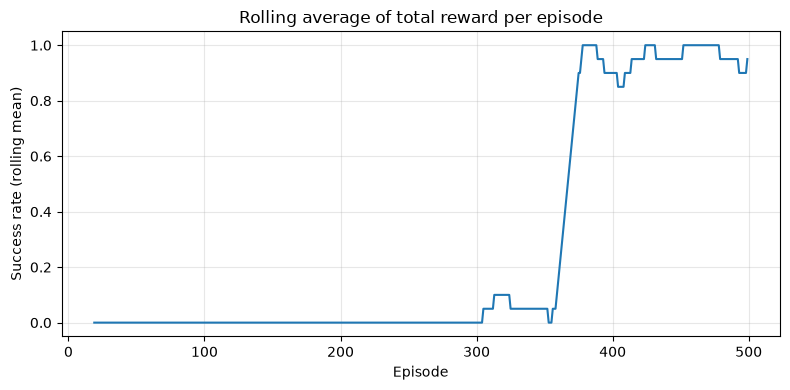

In [236]:
import matplotlib.pyplot as plt

def rolling_average(rewards, window=1000):
    rolling = []
    eps = []
    for i in range(len(rewards) - window + 1):
        rolling.append(sum(rewards[i:i + window]) / window)
        eps.append(i + window - 1)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(eps, rolling)
    ax.set_xlabel("Episode")
    ax.set_ylabel("Success rate (rolling mean)")
    ax.set_title("Rolling average of total reward per episode")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

rolling_average(rewards, 20)

## **4. Extract the greedy policy**

After training, the optimal action from each state is the one with the highest Q-value. We extract it like we did before.

In [237]:
policy = np.array([greedy_action(Q[s]) for s in range(n_states)])
print("Optimal policy (0=left, 1=down, 2=right, 3=up):")
print(policy.reshape(4, 4))

arrows = np.array(["←", "↓", "→", "↑"])
print("Optimal policy as arrows:")
print("\n".join(" ".join(arrows[a] for a in row) for row in policy.reshape(4, 4)))


Optimal policy (0=left, 1=down, 2=right, 3=up):
[[1 0 3 3]
 [1 2 0 2]
 [2 1 1 3]
 [1 2 2 2]]
Optimal policy as arrows:
↓ ← ↑ ↑
↓ → ← →
→ ↓ ↓ ↑
↓ → → →


## **5. Evaluate the learned policy**

Run several test episodes using the greedy policy (no exploration) to confirm it solves the environment.

In [238]:
def test_episode(policy, render=False):
    state, _ = env.reset()
    done = False
    total_reward = 0.0

    while not done:
        action = policy[state]
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        total_reward += reward
        if render:
            print(env.render())
    return total_reward

# Count number of successes
successes = 0
for _ in range(100):
    if test_episode(policy) == 1.0:
        successes += 1
print(f"Successes in 100 greedy runs: {successes}/100")

Successes in 100 greedy runs: 100/100


In [239]:
# Let's actually view step by step what the agent does
test_episode(policy, render=True)

  (Down)
SFFF
FHFH
FFFH
HFFG

  (Down)
SFFF
FHFH
FFFH
HFFG

  (Right)
SFFF
FHFH
FFFH
HFFG

  (Down)
SFFF
FHFH
FFFH
HFFG

  (Right)
SFFF
FHFH
FFFH
HFFG

  (Right)
SFFF
FHFH
FFFH
HFFG



1.0

## **6. GUI animation**

We can re-create the env with `render_mode="human"` to open a window and view the learned policy.

In [240]:
anim_env = gym.make("FrozenLake-v1", 
               render_mode="human", 
               desc = DESC,
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               # success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE
            )

state, _ = anim_env.reset()
done = False
while not done:
    action = policy[state]
    state, reward, terminated, truncated, _ = anim_env.step(action)
    done = terminated or truncated

anim_env.close()

## **7. Experimentation**


Now that you've seen the entire training loop, let's bump up the difficulty. We're providing you with code that solves two problems and you'll be asked to look at the results and answer a few questions.

- Using Q-learning to learn a policy for the agent to navigate the `8x8`, non-slippery world
- Learning a policy on the `8x8` world with `is_slippery=True` and `success_rate = 2/3`.

### **7.1: 8x8, No Slips**

Use Q-learning to learn a policy for the agent to navigate the `8x8`, non-slippery world. Observe the final policy, and print out the sliding window average of rewards over time.

In [241]:
DESC = None
MAP_NAME = "8x8"
IS_SLIPPERY = False
# SUCCESS_RATE = 2.0/3.0
REWARD_SCHEDULE = (1, 0, 0)
MAX_EPISODE_STEPS = 100
PRINTOUT_RATE = 20


env = gym.make("FrozenLake-v1", 
               render_mode="ansi", 
               desc = DESC,
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               # success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE,
               max_episode_steps=MAX_EPISODE_STEPS
            )

n_states = env.observation_space.n
n_actions = env.action_space.n

In [242]:
rewards = []
n_episodes = 20000
ALPHA = 0.1
GAMMA = 0.99
EPSILON = 0.01

Q = np.zeros((n_states, n_actions))

for episode in range(n_episodes):
    total_reward = run_episode(Q, ALPHA, GAMMA, EPSILON)
    
    # When our episode is finished, return the reward
    rewards.append(total_reward)

    # Occasionally print the rolling average reward
    if (episode + 1) % PRINTOUT_RATE == 0:
        rolling = np.mean(rewards[-PRINTOUT_RATE:])
        print(f"Episode {episode + 1}: rolling avg (last {PRINTOUT_RATE}) = {rolling:.2f}")


Episode 20: rolling avg (last 20) = 0.00
Episode 40: rolling avg (last 20) = 0.00
Episode 60: rolling avg (last 20) = 0.00
Episode 80: rolling avg (last 20) = 0.00
Episode 100: rolling avg (last 20) = 0.00
Episode 120: rolling avg (last 20) = 0.00
Episode 140: rolling avg (last 20) = 0.00
Episode 160: rolling avg (last 20) = 0.00
Episode 180: rolling avg (last 20) = 0.00
Episode 200: rolling avg (last 20) = 0.00
Episode 220: rolling avg (last 20) = 0.00
Episode 240: rolling avg (last 20) = 0.00
Episode 260: rolling avg (last 20) = 0.00
Episode 280: rolling avg (last 20) = 0.00
Episode 300: rolling avg (last 20) = 0.00
Episode 320: rolling avg (last 20) = 0.00
Episode 340: rolling avg (last 20) = 0.05
Episode 360: rolling avg (last 20) = 0.00
Episode 380: rolling avg (last 20) = 0.00
Episode 400: rolling avg (last 20) = 0.00
Episode 420: rolling avg (last 20) = 0.00
Episode 440: rolling avg (last 20) = 0.00
Episode 460: rolling avg (last 20) = 0.00
Episode 480: rolling avg (last 20) = 0

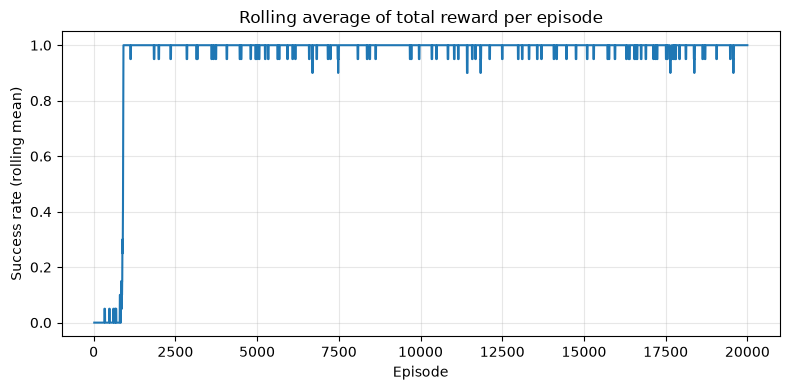

In [243]:
rolling_average(rewards, 20)

In [244]:
policy = np.array([greedy_action(Q[s]) for s in range(n_states)])
print("Optimal policy (0=left, 1=down, 2=right, 3=up):")
print(policy.reshape(8, 8))

arrows = np.array(["←", "↓", "→", "↑"])
print("Optimal policy as arrows:")
print("\n".join(" ".join(arrows[a] for a in row) for row in policy.reshape(8, 8)))


Optimal policy (0=left, 1=down, 2=right, 3=up):
[[2 2 2 2 2 2 2 1]
 [3 3 3 2 3 1 1 1]
 [3 3 2 0 1 2 2 1]
 [1 1 3 2 3 3 1 1]
 [3 3 0 1 0 3 2 1]
 [3 0 1 1 0 0 0 1]
 [3 1 0 0 1 2 2 1]
 [0 1 1 3 3 3 1 0]]
Optimal policy as arrows:
→ → → → → → → ↓
↑ ↑ ↑ → ↑ ↓ ↓ ↓
↑ ↑ → ← ↓ → → ↓
↓ ↓ ↑ → ↑ ↑ ↓ ↓
↑ ↑ ← ↓ ← ↑ → ↓
↑ ← ↓ ↓ ← ← ← ↓
↑ ↓ ← ← ↓ → → ↓
← ↓ ↓ ↑ ↑ ↑ ↓ ←


In [245]:
# View the animated policy...
anim_env = gym.make("FrozenLake-v1", 
               render_mode="human", 
               desc = DESC,
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               # success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE
            )

state, _ = anim_env.reset()
done = False
while not done:
    action = policy[state]
    state, reward, terminated, truncated, _ = anim_env.step(action)
    done = terminated or truncated

anim_env.close()

<!-- BEGIN QUESTION -->

#### **Exercise 7.1 (Written): Describing the Learned Policy**

Answer the following questions:
- Observe the extracted policy, and view how the agent in the GUI navigates the world. Describe the policy and behavior of the agent in your own words.
- Observe the sliding window average of the final rewards over time, how long did it take train? You'll notice that there is a stretch of low average final reward, but then improves rapidly. Why is this the case?

- The agent learns the policy towards the goal that leads to the least negative rewards. At the beginning, the agent moves around seemingly randomly because it has not learned the policy and which actions are better. It even failed and bumped into the water puddle once. As it progresses, it learns what actions to take and ended up choosing a much more efficient path. Eventually, the agent is able to learn the policy to reach the goal consistently without making unnecessary moves.
- The sliding window stayed relatively low during the beginning of the training because the agent has not discovered the action towards the most rewards. Once the agent successfully reached the goal and receives the positive award, Q-learning begins updating the values of actions that lead towards the goal. This results in a more rapid improvement because the values propagates through earlier states over multiple episodes.

<!-- END QUESTION -->

### **7.2: 8x8, With Slips**


Let's learn a policy with `IS_SLIPPERY = True` and the `success_rate = 2/3`. Reminder that this means that when an agent takes an action, there is a 2/3 chance that it will correctly take its intended action, but there is a chance it will slip perpendicular to its intended direction (e.g. if it's moving left or right, it might slip up or down (and vice versa))

<!-- BEGIN QUESTION -->

Pause. Before running any more code, answer the following:

- A) Do you think it will take a longer or shorter number of episodes for the agent to find a good policy for this scenario compared the previous question? Why?
- B) What do you expect the sliding window plot of the rewards per episode to look like as we continue training? Why?
- C) What do you think a good policy for this world looks like? Imagine if *you* are the one controlling the agent - what would you do at each step? What would be your general strategy so that you safely get to the goal? How does this strategy differ than what you might do in a non-slippery world?

- A) I think it will take a longer number of episodes for the agent to find a good policy in this case because the agent can no longer guarantee to take the action that it chooses so it is more likely to choose the wrong ones instead of the ones learned from before.
- B) I expect the sliding window the stay low at the beginning and gradually increase as the number of episodes increases. This is because the agent will learn a better policy. However, there is a chance that it won't reach the perfect average reward because the actions are not guaranteed for the agent therefore there will be some randomness even with good training.
- C) I think a good policy would be to prioritize safety instead of finding the most optimal path. Since there will always be some randomness and fluctuation for the model, I would make sure that it steers away from holes first and choose paths that have more safe space around them. I would also consider where I might end up if I slip in a different direction.


<!-- END QUESTION -->

Now, let's learn a policy on the slippery 8x8 world.

**NOTES** 
- We're giving you some default values for $\alpha$ and $\gamma$, as this is a harder problem. However feel free to change them to see how it influences the training. 
- In addition, you may notice that we've upped `n_episodes` up to `50000`, you'll see why.
- For this many episodes, use a rolling window plot size of `1000` to observe the training curve.
- **You'll want to try this multiple times** to get a feel for the types of policies and learning curves this problem generates.


In [246]:
DESC = None
MAP_NAME = "8x8"
IS_SLIPPERY = True
SUCCESS_RATE = 2.0/3.0
REWARD_SCHEDULE = (1, 0, 0)
MAX_EPISODE_STEPS = 100

env = gym.make("FrozenLake-v1", 
               render_mode="ansi", 
               desc = DESC,
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE,
               max_episode_steps=MAX_EPISODE_STEPS
            )

n_states = env.observation_space.n
n_actions = env.action_space.n

In [247]:
rewards = []
n_episodes = 50000
ALPHA = 0.05
GAMMA = 0.99
EPSILON = 0.01

Q = np.zeros((n_states, n_actions))

for episode in range(n_episodes):
    total_reward = run_episode(Q, ALPHA, GAMMA, EPSILON)
    
    # When our episode is finished, return the reward
    rewards.append(total_reward)

    # Occasionally print the rolling average reward
    if (episode + 1) % 200 == 0:
        rolling = np.mean(rewards[-1000:])
        print(f"Episode {episode + 1}: rolling avg (last 1000) = {rolling:.2f}")

print(f"Average reward over last 100 episodes: {np.mean(rewards[-100:]):.2f}")

Episode 200: rolling avg (last 1000) = 0.01
Episode 400: rolling avg (last 1000) = 0.00
Episode 600: rolling avg (last 1000) = 0.01
Episode 800: rolling avg (last 1000) = 0.03
Episode 1000: rolling avg (last 1000) = 0.04
Episode 1200: rolling avg (last 1000) = 0.05
Episode 1400: rolling avg (last 1000) = 0.07
Episode 1600: rolling avg (last 1000) = 0.08
Episode 1800: rolling avg (last 1000) = 0.07
Episode 2000: rolling avg (last 1000) = 0.07
Episode 2200: rolling avg (last 1000) = 0.07
Episode 2400: rolling avg (last 1000) = 0.07
Episode 2600: rolling avg (last 1000) = 0.08
Episode 2800: rolling avg (last 1000) = 0.12
Episode 3000: rolling avg (last 1000) = 0.14
Episode 3200: rolling avg (last 1000) = 0.15
Episode 3400: rolling avg (last 1000) = 0.18
Episode 3600: rolling avg (last 1000) = 0.19
Episode 3800: rolling avg (last 1000) = 0.18
Episode 4000: rolling avg (last 1000) = 0.19
Episode 4200: rolling avg (last 1000) = 0.29
Episode 4400: rolling avg (last 1000) = 0.38
Episode 4600: 

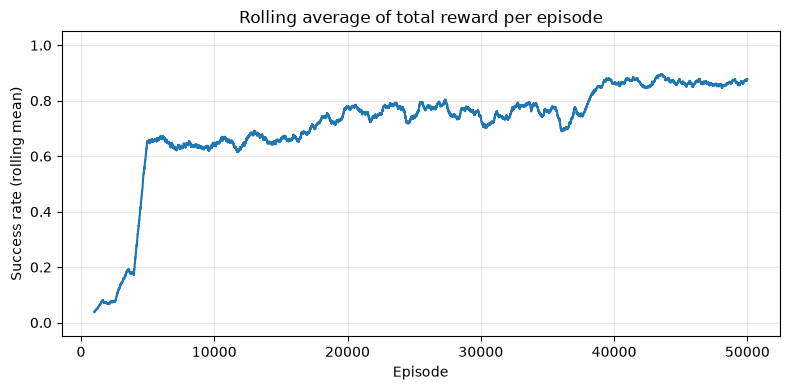

In [248]:
rolling_average(rewards, 1000)

In [249]:
policy = np.array([greedy_action(Q[s]) for s in range(n_states)])
print("Optimal policy (0=left, 1=down, 2=right, 3=up):")
print(policy.reshape(8, 8))

arrows = np.array(["←", "↓", "→", "↑"])
print("Optimal policy as arrows:")
print("\n".join(" ".join(arrows[a] for a in row) for row in policy.reshape(8, 8)))


Optimal policy (0=left, 1=down, 2=right, 3=up):
[[2 2 2 2 2 2 1 1]
 [2 2 3 3 2 2 2 1]
 [1 3 0 3 2 3 2 1]
 [3 3 1 1 3 3 2 1]
 [3 3 2 1 2 2 3 1]
 [2 0 2 3 0 3 0 2]
 [0 3 3 3 3 3 2 2]
 [1 2 2 1 0 0 2 0]]
Optimal policy as arrows:
→ → → → → → ↓ ↓
→ → ↑ ↑ → → → ↓
↓ ↑ ← ↑ → ↑ → ↓
↑ ↑ ↓ ↓ ↑ ↑ → ↓
↑ ↑ → ↓ → → ↑ ↓
→ ← → ↑ ← ↑ ← →
← ↑ ↑ ↑ ↑ ↑ → →
↓ → → ↓ ← ← → ←


In [250]:
# View the animated policy...
anim_env = gym.make("FrozenLake-v1", 
               render_mode="human", 
               desc = DESC,
               map_name = MAP_NAME,
               is_slippery=IS_SLIPPERY, 
               success_rate = SUCCESS_RATE,
               reward_schedule=REWARD_SCHEDULE
            )

state, _ = anim_env.reset()
done = False
while not done:
    action = policy[state]
    state, reward, terminated, truncated, _ = anim_env.step(action)
    done = terminated or truncated

anim_env.close()

<!-- BEGIN QUESTION -->

Answer the following questions:
- After running the above code a few times, compare your predictions from 7.2.A and 7.2.B to your actual results. What do you see?
- Observe the learned policy visually (or through the GUI). Describe in your own words what the agent has learned. How does it compare to your prediction in 7.2.C? 
- You may notice that in some runs, the policy looks somewhat strange for the two states directly above the goal... why is this policy actually good for the agent given the rules of the world and the reward structure?

- My predictions were mostly correct. The agent generaly takes longer to learn a good policy in the slippery world compared to the non-slippery world because its movements are less predictable. The sliding window average rewards also fluctuated a lot more and does not consistently reach 1.0. Even after learned a good policy, the agent can still fail because of random slipping.
- The agent learns to prioritize safer routes rather than simply taking the shortest path to the goal. It generally tries to avoid the holes and choose actions that give it a better chance of reaching the goal even if it slips. This is similar to my predict in 7.2.C.
- The two states above the goal seems strange because they do not point to the goal. This is because the movement is slippery, meaning the agent could end up moving in a different direction than intended. By choosing an action that accounts for this slippery while reducing the risk to fall into the hole, it maximizes its chance of reaching the goal because it only gets positive reward once it reaches the goal rather than getting closer to it.



<!-- END QUESTION -->

### **Reward Shaping**

Currently, this is an environment with *sparse* rewards. The agent has to wander for a long amount of time before randomly stumbling into the goal state - and only then can it start pushing that information back through the Q-table to act on. 

If this world were to get any bigger, the chances of this happening get smaller and smaller. 

*Reward shaping* is the concept of giving our agent intermediate rewards to help guide it along it's path. A natural way to shape rewards in this problem is to give the agent a *negative* reward for falling into a hole. 

While this doesn't directly guide the agent to the goal, it will give the agent a sense of which spaces to *avoid*.


<!-- BEGIN QUESTION -->

Do the following:
- First, run 4 Q-learning training runs with what you already have (sparse rewards). Take screenshots of the plots with a window size of `1000`.
- Edit `REWARD_SCHEDULE` to give the agent falling in the hole a reward of `-1`. Then, run your Q-learning training again 4 more times, taking snapshots of the training curve.

Then answer the following question:
- Compare your learning plots from the sparse rewards to the learning plots you got after adding a negative reward for falling in the hole. What do you see? Why does this happen?



The sparse-reward curves began low and improved in stages, with noticeable differences between runs.  Adding a −1 reward for falling into a hole improved early learning in these trials: the average goal rate during the first 1,000 episodes increased from 5.5% to 47.8%. The penalty curves generally reached their plateau sooner, although all curves continued to fluctuate. This happens because sparse rewards provide no distinction between falling into a hole and surviving without reaching the goal: both give zero reward. A hole penalty immediately reduces the Q-values of actions that lead into holes, and this information propagates to earlier states through subsequent updates. The agent can therefore learn which actions to avoid before discovering a reliable route to the goal.

<!-- END QUESTION -->

## **8. Collaboration Statement**

You are required to complete the following collaboration statement.


<!-- BEGIN QUESTION -->

- If you completed the lab in a group - list all your group members here, including yourself. **If you worked individually, you must state *"I worked by myself."***
    - I worked by myself.
- You must list the names of any others you got help from when completing this assignment (including TAs), and in what way you worked with them (discussed ideas, debugged math). **If you did not collaborate at all, you must state *"I did not collaborate with anyone else."***
    - I did not collaborate with anyone else.
- If you found any resources online helpful, you must link them and describe how you found them helpful (or not helpful). **If you did not use any resources online, you must state *"I did not use any resources online."***
    - I used Google and Gemni to search up terms. 
- If you used any AI assistive technologies, you must describe how you used them and how you found them helpful (or not helpful). **If you did not use any AI assistive technologies, you must state *"I did not use any AI assistive technologies."***
    - I used Gemni to look up some terms.
- If you have any questions or comments about the material, or there was a topic or question you are confused about -- please make a note of it here! **If you do not have any questions or comments, you must state *"I do not have any questions or comments about the assignment."***
    - I do not have any questions or comments about the assignment.
- Estimate how long this assignment took you in hours. **You must give an estimate**.
    - This assignment took me about 5 hours to complete.


<!-- END QUESTION -->



## Submission

Make sure you have run all cells in your notebook in order before running the cell below, so that all images/graphs appear in the output. The cell below will generate a zip file for you to submit. **Please save before exporting!**

Run every cell from top to bottom and SAVE before exporting. Then submit
the generated .zip to the HW9 autograder assignment on Gradescope.


In [251]:
# Save your notebook first, then run this cell to export your submission.
grader.export(pdf=False, run_tests=True)

Running your submission against local test cases...


Your submission received the following results when run against available test cases:

    q_greedy_action results: All test cases passed!

    q_update results: All test cases passed!
